In [1]:
!pip install eyelinkparser
!pip install time_series_test


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.3/108.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 8.4 MB/s eta 0:00:00


In [2]:

from google.colab import drive
drive.mount('/content/drive')
import os
import pandas as pd
import csv
import numpy as np
from eyelinkparser import parse, defaulttraceprocessor
from datamatrix import series as srs
import numpy as np
import matplotlib.pyplot as plt
import glob
from datamatrix import io, operations as ops, DataMatrix, SeriesColumn

import eyelinkparser as ep
from datamatrix import series as srs


Mounted at /content/drive


# Preprocess the pupil data

In [ ]:

PUPIL_COL_RSVP = "ptrace_RSVP"
PUPIL_COL_FIX  = "ptrace_Fixation"
TTRACE_COL_FIX = "ttrace_Fixation"
TTRACE_COL_RSVP = "ttrace_RSVP"

BASELINE_TIME_MS = 100          # last 100 ms of fixation (based on ttrace)
BASELINE_NAN_MAX_PROP = 0.50    # drop trial if >50% NaN in baseline window


RSVP_WIN_START_MS = 200
RSVP_WIN_END_MS   = 1200
RSVP_WIN_NAN_MAX_PROP = 0.10

ROBUST_Z_THRESH = 3
ROBUST_Z_CONST = 0.6745


def _mad(x):
    """Median absolute deviation (MAD), ignoring NaNs."""
    med = np.nanmedian(x)
    return np.nanmedian(np.abs(x - med))


def load_fix_to_iti(
    folder,
    asc_encoding="windows-1252",
    downsample=10,
    drop_first_n=0,
    baseline_time_ms=BASELINE_TIME_MS,
    baseline_nan_max_prop=BASELINE_NAN_MAX_PROP,
    rsvp_win_start_ms=RSVP_WIN_START_MS,
    rsvp_win_end_ms=RSVP_WIN_END_MS,
    rsvp_win_nan_max_prop=RSVP_WIN_NAN_MAX_PROP,
    robust_z_thresh=ROBUST_Z_THRESH,
    verbose=True,
):

    dm = ep.parse(
        folder=folder,
        ext=".asc",
        edf2asc_binary=None,
        asc_encoding=asc_encoding,
        pupil_size=True,
        time_trace=True,
        gaze_pos=False,
        traceprocessor=ep.defaulttraceprocessor(
            blinkreconstruct=True,
            downsample=downsample,
            mode="advanced",
        ),
    )

    pid = os.path.basename(folder.rstrip(os.sep))

    n_parsed = len(dm)
    print(dm)

    # Drop first 20 trials as they are practice
    if drop_first_n and len(dm) > drop_first_n:
        dm = dm[drop_first_n:]

    n_after_drop_first_n = len(dm)
    n_removed_drop_first_n = n_parsed - n_after_drop_first_n

    # Pull traces to numpy for baseline computations
    t_fix = np.asarray(dm[TTRACE_COL_FIX], dtype=float)   # (n_trials, n_time)
    p_fix = np.asarray(dm[PUPIL_COL_FIX], dtype=float)    # (n_trials, n_time)

    # Time-lock fixation trace to its first timestamp (per trial)
    t_fix = t_fix - t_fix[:, [0]]

    n_trials = len(dm)
    baseline = np.full(n_trials, np.nan, dtype=float)
    baseline_nan_prop = np.full(n_trials, np.nan, dtype=float)

    # 2-4) Compute baseline; mark trials with too many NaNs in baseline window
    keep = np.ones(n_trials, dtype=bool)

    for i in range(n_trials):
        ti = t_fix[i]
        pi = p_fix[i]

        # If timing is entirely NaN, can't define baseline window
        if np.all(np.isnan(ti)):
            keep[i] = False
            continue

        t_end = np.nanmax(ti)
        t0 = t_end - baseline_time_ms

        # Define baseline window by time
        win = (ti >= t0) & (ti <= t_end)

        # If no samples fall in the window, drop
        if not np.any(win):
            keep[i] = False
            continue

        pi_win = pi[win]
        n_win = pi_win.size
        n_nan = np.isnan(pi_win).sum()
        nan_prop = n_nan / n_win if n_win else np.nan
        baseline_nan_prop[i] = nan_prop

        # Drop if NaN proportion too high
        if np.isnan(nan_prop) or (nan_prop > baseline_nan_max_prop):
            keep[i] = False
            continue

        # Baseline = mean of non-NaN samples within window
        baseline[i] = np.nanmean(pi_win)

        # If mean still NaN, drop
        if np.isnan(baseline[i]):
            keep[i] = False

    n_after_baseline = int(keep.sum())
    n_removed_baseline = n_trials - n_after_baseline

    # Keep only trials that passed baseline QC
    keep_idx = np.flatnonzero(keep).tolist()
    dm = dm[keep_idx]

    # Store QC columns aligned with the kept dm
    dm.baseline_fix_last100 = baseline[keep]
    dm.baseline_fix_last100_nanprop = baseline_nan_prop[keep]

    # 5) Baseline-correct RSVP trace (explicit broadcasting)
    rsvp = np.asarray(dm[PUPIL_COL_RSVP], dtype=float)               # (n_trials_kept, n_time)
    bl = np.asarray(dm.baseline_fix_last100, dtype=float)[:, None]  # (n_trials_kept, 1)
    rsvp_bc = rsvp - bl
    dm[PUPIL_COL_RSVP] = rsvp_bc

    # 6) Robust z-score outlier removal based on windowed mean during RSVP
    n_before_rsvp_window_qc = len(dm)
    n_removed_rsvp_window_qc = 0
    n_removed_robust_z = 0

    if robust_z_thresh is not None and len(dm) > 2:

        t_rsvp = np.asarray(dm[TTRACE_COL_RSVP], dtype=float)  # (n_trials_kept, n_time)
        # Time-lock RSVP trace to its first timestamp (per trial)
        t_rsvp = t_rsvp - t_rsvp[:, [0]]

        n_trials2 = len(dm)
        trial_scalar = np.full(n_trials2, np.nan, dtype=float)
        rsvp_win_nanprop = np.full(n_trials2, np.nan, dtype=float)

        keep2 = np.ones(n_trials2, dtype=bool)

        for i in range(n_trials2):
            ti = t_rsvp[i]
            pi = rsvp_bc[i]

            if np.all(np.isnan(ti)):
                keep2[i] = False
                continue

            win = (ti >= rsvp_win_start_ms) & (ti <= rsvp_win_end_ms)

            if not np.any(win):
                keep2[i] = False
                continue

            pi_win = pi[win]
            n_win = pi_win.size
            n_nan = np.isnan(pi_win).sum()
            nan_prop = n_nan / n_win if n_win else np.nan
            rsvp_win_nanprop[i] = nan_prop

            if np.isnan(nan_prop) or (nan_prop > rsvp_win_nan_max_prop):
                keep2[i] = False
                continue

            trial_scalar[i] = np.nanmean(pi_win)
            if np.isnan(trial_scalar[i]):
                keep2[i] = False

        # Save these (still aligned to current dm BEFORE filtering with keep2)
        dm.rsvp_win_mean = trial_scalar
        dm.rsvp_win_nanprop = rsvp_win_nanprop

        n_after_rsvp_window_qc = int(keep2.sum())
        n_removed_rsvp_window_qc = n_before_rsvp_window_qc - n_after_rsvp_window_qc

        dm = dm[np.flatnonzero(keep2).tolist()]

        # Now compute robust z across remaining trials
        x = np.asarray(dm.rsvp_win_mean, dtype=float)
        med = np.nanmedian(x)
        mad = _mad(x)

        # If MAD is zero/NaN, skip robust z filtering
        if np.isfinite(mad) and mad > 0:
            z_robust = ROBUST_Z_CONST * (x - med) / mad
            dm.rsvp_win_robust_z = z_robust

            keep3 = np.isfinite(z_robust) & (np.abs(z_robust) <= robust_z_thresh)
            n_after_robust_z = int(keep3.sum())
            n_removed_robust_z = len(dm) - n_after_robust_z

            dm = dm[np.flatnonzero(keep3).tolist()]
        else:
            dm.rsvp_win_robust_z = np.nan

    if verbose:
        print(
            f"{pid}: "
            f"parsed={n_parsed} | "
            f"removed_drop_first_n={n_removed_drop_first_n} -> {n_after_drop_first_n} | "
            f"removed_baseline_qc={n_removed_baseline} -> {n_after_baseline} | "
            f"removed_rsvp_window_qc={n_removed_rsvp_window_qc} | "
            f"removed_robust_z(|z|>{robust_z_thresh})={n_removed_robust_z} | "
            f"final={len(dm)}"
        )

    return dm


# ---------- Batch processing + saving ----------
#base_folder = r"/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Main"
#save_folder = r"/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Processed_DM"

########### Temp processing
base_folder = r"/content/drive/MyDrive/Temp"
save_folder = r"/content/drive/MyDrive/Temp//Processed_DM"


#######################
os.makedirs(save_folder, exist_ok=True)

participant_dirs = sorted(
    d for d in glob.glob(os.path.join(base_folder, "P*"))
    if os.path.isdir(d)
)

all_dms = {}

for pdir in participant_dirs:
    pid = os.path.basename(pdir)

    dm = load_fix_to_iti(pdir, verbose=True)
    all_dms[pid] = dm

    out_file = os.path.join(save_folder, f"{pid}_dm_preprocessed.dm")
    io.writebin(dm, out_file)



+---+
| # |
+---+
+---+


AttributeError: No column named "ttrace_Fixation"

# New Preprocessing

In [8]:
import os
import glob
import numpy as np
from datamatrix import io
import eyelinkparser as ep

# -----------------------
# PATHS
# -----------------------
base_folder = r"/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Main"
save_folder = r"/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Updated_Preprocessed_Data"
os.makedirs(save_folder, exist_ok=True)

# -----------------------
# COLUMN NAMES
# -----------------------
PUPIL_COL_RSVP = "ptrace_RSVP"
PUPIL_COL_FIX = "ptrace_Fixation"
TTRACE_COL_FIX = "ttrace_Fixation"
TTRACE_COL_RSVP = "ttrace_RSVP"

# -----------------------
# PARAMETERS
# -----------------------
DROP_FIRST_N = 0

BASELINE_TIME_MS = 100
BASELINE_NAN_MAX_PROP = 0.50

EARLY_RSVP_QC_END_MS = 100
EARLY_RSVP_NAN_MAX_PROP = 0.30

RSVP_WIN_START_MS = 200
RSVP_WIN_END_MS = 1200
RSVP_WIN_NAN_MAX_PROP = 0.10

ROBUST_Z_THRESH = 3
ROBUST_Z_CONST = 0.6745

SMOOTH_WINDOW = 5   # samples; set to 1 or None to disable

ASC_ENCODING = "windows-1252"
DOWNSAMPLE = 10

# -----------------------
# HELPERS
# -----------------------
def _mad(x):
    med = np.nanmedian(x)
    return np.nanmedian(np.abs(x - med))

def _align_to_first_valid(T):
    T = np.asarray(T, dtype=float).copy()
    valid = ~np.isnan(T)
    any_valid = valid.any(axis=1)
    first_idx = np.argmax(valid, axis=1)
    t0 = np.full(T.shape[0], np.nan, dtype=float)
    t0[any_valid] = T[np.arange(T.shape[0])[any_valid], first_idx[any_valid]]
    return T - t0[:, None]

def _nan_moving_average_1d(x, win=5):
    if win is None or win <= 1:
        return np.asarray(x, dtype=float).copy()
    x = np.asarray(x, dtype=float)
    y = np.full_like(x, np.nan, dtype=float)
    half = win // 2
    for i in range(len(x)):
        lo = max(0, i - half)
        hi = min(len(x), i + half + 1)
        seg = x[lo:hi]
        if np.all(np.isnan(seg)):
            continue
        y[i] = np.nanmean(seg)
    return y

def _smooth_2d(X, win=5):
    X = np.asarray(X, dtype=float)
    if win is None or win <= 1:
        return X.copy()
    Y = np.full_like(X, np.nan, dtype=float)
    for i in range(X.shape[0]):
        Y[i] = _nan_moving_average_1d(X[i], win=win)
    return Y

# -----------------------
# MAIN PREPROCESSING
# -----------------------
def load_fix_to_iti(
    folder,
    asc_encoding=ASC_ENCODING,
    downsample=DOWNSAMPLE,
    drop_first_n=DROP_FIRST_N,
    baseline_time_ms=BASELINE_TIME_MS,
    baseline_nan_max_prop=BASELINE_NAN_MAX_PROP,
    early_rsvp_qc_end_ms=EARLY_RSVP_QC_END_MS,
    early_rsvp_nan_max_prop=EARLY_RSVP_NAN_MAX_PROP,
    rsvp_win_start_ms=RSVP_WIN_START_MS,
    rsvp_win_end_ms=RSVP_WIN_END_MS,
    rsvp_win_nan_max_prop=RSVP_WIN_NAN_MAX_PROP,
    robust_z_thresh=ROBUST_Z_THRESH,
    smooth_window=SMOOTH_WINDOW,
    verbose=True,
):
    dm = ep.parse(
        folder=folder,
        ext=".asc",
        edf2asc_binary=None,
        asc_encoding=asc_encoding,
        pupil_size=True,
        time_trace=True,
        gaze_pos=False,
        traceprocessor=ep.defaulttraceprocessor(
            blinkreconstruct=True,
            downsample=downsample,
            mode="advanced",
        ),
    )

    pid = os.path.basename(folder.rstrip(os.sep))
    n_parsed = len(dm)

    # -----------------------
    # DROP PRACTICE / EARLY TRIALS
    # -----------------------
    if drop_first_n and len(dm) > drop_first_n:
        dm = dm[drop_first_n:]

    n_after_drop_first_n = len(dm)
    n_removed_drop_first_n = n_parsed - n_after_drop_first_n

    # -----------------------
    # FIXATION-BASED BASELINE
    # -----------------------
    t_fix = _align_to_first_valid(dm[TTRACE_COL_FIX])
    p_fix = np.asarray(dm[PUPIL_COL_FIX], dtype=float)

    n_trials = len(dm)
    baseline = np.full(n_trials, np.nan, dtype=float)
    baseline_nan_prop = np.full(n_trials, np.nan, dtype=float)
    keep_baseline = np.ones(n_trials, dtype=bool)

    for i in range(n_trials):
        ti = t_fix[i]
        pi = p_fix[i]

        if np.all(np.isnan(ti)):
            keep_baseline[i] = False
            continue

        t_end = np.nanmax(ti)
        t_start = t_end - baseline_time_ms
        win = (ti >= t_start) & (ti <= t_end)

        if not np.any(win):
            keep_baseline[i] = False
            continue

        pi_win = pi[win]
        n_win = pi_win.size
        n_nan = np.isnan(pi_win).sum()
        nan_prop = n_nan / n_win if n_win else np.nan
        baseline_nan_prop[i] = nan_prop

        if np.isnan(nan_prop) or nan_prop > baseline_nan_max_prop:
            keep_baseline[i] = False
            continue

        baseline[i] = np.nanmean(pi_win)

        if not np.isfinite(baseline[i]):
            keep_baseline[i] = False

    n_removed_baseline = int((~keep_baseline).sum())
    dm = dm[np.flatnonzero(keep_baseline).tolist()]
    dm.baseline_fix_last100 = baseline[keep_baseline]
    dm.baseline_fix_last100_nanprop = baseline_nan_prop[keep_baseline]

    # -----------------------
    # BASELINE-CORRECT RSVP
    # -----------------------
    rsvp = np.asarray(dm[PUPIL_COL_RSVP], dtype=float)
    bl = np.asarray(dm.baseline_fix_last100, dtype=float)[:, None]
    rsvp_bc = rsvp - bl

    if smooth_window is not None and smooth_window > 1:
        rsvp_bc = _smooth_2d(rsvp_bc, win=smooth_window)

    dm[PUPIL_COL_RSVP] = rsvp_bc

    # -----------------------
    # EARLY RSVP QC
    # -----------------------
    t_rsvp = _align_to_first_valid(dm[TTRACE_COL_RSVP])

    early_nanprop = np.full(len(dm), np.nan, dtype=float)
    keep_early = np.ones(len(dm), dtype=bool)

    for i in range(len(dm)):
        ti = t_rsvp[i]
        pi = rsvp_bc[i]

        win = (ti >= 0) & (ti <= early_rsvp_qc_end_ms)
        if not np.any(win):
            keep_early[i] = False
            continue

        seg = pi[win]
        nan_prop = np.isnan(seg).sum() / len(seg)
        early_nanprop[i] = nan_prop

        if np.isnan(nan_prop) or nan_prop > early_rsvp_nan_max_prop:
            keep_early[i] = False

    n_removed_early = int((~keep_early).sum())
    dm.early_rsvp_nanprop = early_nanprop
    dm = dm[np.flatnonzero(keep_early).tolist()]

    # -----------------------
    # RSVP WINDOW QC
    # -----------------------
    n_before_rsvp_window_qc = len(dm)
    n_removed_rsvp_window_qc = 0
    n_removed_robust_z = 0

    if robust_z_thresh is not None and len(dm) > 2:
        t_rsvp = _align_to_first_valid(dm[TTRACE_COL_RSVP])
        rsvp_bc = np.asarray(dm[PUPIL_COL_RSVP], dtype=float)

        trial_scalar = np.full(len(dm), np.nan, dtype=float)
        rsvp_win_nanprop = np.full(len(dm), np.nan, dtype=float)
        keep_rsvp = np.ones(len(dm), dtype=bool)

        for i in range(len(dm)):
            ti = t_rsvp[i]
            pi = rsvp_bc[i]

            if np.all(np.isnan(ti)):
                keep_rsvp[i] = False
                continue

            win = (ti >= rsvp_win_start_ms) & (ti <= rsvp_win_end_ms)
            if not np.any(win):
                keep_rsvp[i] = False
                continue

            seg = pi[win]
            n_win = seg.size
            n_nan = np.isnan(seg).sum()
            nan_prop = n_nan / n_win if n_win else np.nan
            rsvp_win_nanprop[i] = nan_prop

            if np.isnan(nan_prop) or nan_prop > rsvp_win_nan_max_prop:
                keep_rsvp[i] = False
                continue

            trial_scalar[i] = np.nanmean(seg)

            if not np.isfinite(trial_scalar[i]):
                keep_rsvp[i] = False

        dm.rsvp_win_mean = trial_scalar
        dm.rsvp_win_nanprop = rsvp_win_nanprop

        n_removed_rsvp_window_qc = int((~keep_rsvp).sum())
        dm = dm[np.flatnonzero(keep_rsvp).tolist()]

        x = np.asarray(dm.rsvp_win_mean, dtype=float)
        med = np.nanmedian(x)
        mad = _mad(x)

        if np.isfinite(mad) and mad > 0:
            z_robust = ROBUST_Z_CONST * (x - med) / mad
            dm.rsvp_win_robust_z = z_robust
            keep_z = np.isfinite(z_robust) & (np.abs(z_robust) <= robust_z_thresh)
            n_removed_robust_z = int((~keep_z).sum())
            dm = dm[np.flatnonzero(keep_z).tolist()]
        else:
            dm.rsvp_win_robust_z = np.nan

    if verbose:
        print(
            f"{pid}: "
            f"parsed={n_parsed} | "
            f"removed_drop_first_n={n_removed_drop_first_n} -> {n_after_drop_first_n} | "
            f"removed_baseline_qc={n_removed_baseline} | "
            f"removed_early_rsvp_qc={n_removed_early} | "
            f"removed_rsvp_window_qc={n_removed_rsvp_window_qc} | "
            f"removed_robust_z={n_removed_robust_z} | "
            f"final={len(dm)}"
        )

    return dm

# -----------------------
# BATCH PROCESS + SAVE
# -----------------------
participant_dirs = sorted(
    d for d in glob.glob(os.path.join(base_folder, "P*"))
    if os.path.isdir(d)
)

all_dms = {}

for pdir in participant_dirs:
    pid = os.path.basename(pdir)
    print(f"\nProcessing {pid} ...")
    dm = load_fix_to_iti(pdir, verbose=True)
    all_dms[pid] = dm

    out_file = os.path.join(save_folder, f"{pid}_dm_preprocessed.dm")
    io.writebin(dm, out_file)
    print(f"Saved: {out_file}")

print(f"\nDone. Saved {len(all_dms)} participant files to:\n{save_folder}")


Processing P0 ...
.......

/usr/local/lib/python3.12/dist-packages/datamatrix/series.py:1648: RuntimeWarning: Mean of empty slice
  return fnc(a.reshape(-1, by), axis=1)


.....................................................................................................................................................................................................................................................................................................P0: parsed=300 | removed_drop_first_n=0 -> 300 | removed_baseline_qc=6 | removed_early_rsvp_qc=1 | removed_rsvp_window_qc=0 | removed_robust_z=6 | final=287
Saved: /content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Updated_Preprocessed_Data/P0_dm_preprocessed.dm

Processing P1 ...
................................................................................................................................................................................................................................................................................................................................P1: parsed=320 | removed_drop_first_n=0 -> 320 | removed_bas

/usr/local/lib/python3.12/dist-packages/datamatrix/py3compat.py:105: UserWarning: input array must be larger than window size
  warnings.warn(safe_str(msg), *args)
/usr/local/lib/python3.12/dist-packages/datamatrix/_datamatrix/_blinkreconstruct.py:117: RuntimeWarning: Mean of empty slice.
  (a < (a.mean() - std_thr * a.std())) |
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:218: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:175: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:210: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type

..............................................................................................................................................................................................................................................................P11: parsed=300 | removed_drop_first_n=0 -> 300 | removed_baseline_qc=6 | removed_early_rsvp_qc=0 | removed_rsvp_window_qc=13 | removed_robust_z=4 | final=277
Saved: /content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Updated_Preprocessed_Data/P11_dm_preprocessed.dm

Processing P12 ...
............................................................................................................................................................................................................................................................................................................P12: parsed=300 | removed_drop_first_n=0 -> 300 | removed_baseline_qc=1 | removed_early_rsvp_qc=0 | removed_rsvp_wi

## Read the column names

In [7]:
dm = io.readbin("/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Processed_DM/P0_dm_preprocessed.dm")

for col in dm.column_names:
    values = [dm[col][i] for i in range(min(15, len(dm)))]
    print(f"{col:25} | {values}")


Practice                  | [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
T1_expr                   | ['happy', 'happy', 'happy', 'happy', 'happy', 'happy', 'happy', 'happy', 'happy', 'happy', 'happy', 'happy', 'happy', 'happy', 'happy']
T1_letter                 | ['H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H']
T1_pos                    | [6, 4, 4, 5, 4, 6, 6, 6, 4, 6, 4, 6, 6, 5, 6]
T2_expr                   | ['angry', 'angry', 'angry', 'angry', 'angry', 'angry', 'angry', 'angry', 'angry', 'angry', 'angry', 'angry', 'angry', 'angry', 'angry']
T2_letter                 | ['A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A']
T2_pos                    | [8, 9, '', 7, 5, 9, 7, 9, 9, 11, 5, '', 7, '', 9]
acc                       | ['undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined', 'undefined']
accuracy      

## Looking at participant wise data

In [9]:


# ---------- settings ----------
save_folder = r"/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Updated_Preprocessed_Data"

PUPIL_COL = "ptrace_RSVP"
TTRACE_COL = "ttrace_RSVP"

T0_MODE = "start"
T_MIN_MS, T_MAX_MS = 0, 2000

TRIAL_ALPHA = 0.12
TRIAL_LW = 1.0
MAX_TRIALS_TO_PLOT = None
MISSING_FRAC_THRESHOLD = 0.01



def make_time_axis_ms(dm):
    """Median time axis across trials; optionally zero at trial start; return (x_ms, keep_mask)."""
    T = np.asarray(dm[TTRACE_COL], dtype=float)
    if T0_MODE == "start":
        T = T - T[:, [0]]
    x_ms = np.nanmedian(T, axis=0)


    if np.isnan(x_ms).any():
        idx = np.arange(x_ms.size)
        good = ~np.isnan(x_ms)
        x_ms = np.interp(idx, idx[good], x_ms[good]) if good.sum() >= 2 else idx.astype(float)

    keep = (x_ms >= T_MIN_MS) & (x_ms <= T_MAX_MS)
    return x_ms, keep


def report_missing(dm, pid, keep):
    Y = np.asarray(dm[PUPIL_COL], dtype=float)           # (trials, depth)
    frac = np.mean(np.isnan(Y[:, keep]), axis=1)
    broken = frac >= MISSING_FRAC_THRESHOLD
    n_broken, n_trials = int(broken.sum()), Y.shape[0]

    if n_broken == 0:
        print(f"{pid}: 0/{n_trials} broken trials in [{T_MIN_MS},{T_MAX_MS}] ms")
        return

    worst = np.argsort(frac)[::-1]
    worst = worst[broken[worst]][:10]
    worst_str = ", ".join([f"{i}({frac[i]*100:.1f}%)" for i in worst])
    print(f"{pid}: {n_broken}/{n_trials} broken trials (>= {MISSING_FRAC_THRESHOLD*100:.1f}% NaNs)")
    print(f"  worst: {worst_str}")


def plot_trials(dm, pid, x_ms, keep):
    Y = np.asarray(dm[PUPIL_COL], dtype=float)
    if MAX_TRIALS_TO_PLOT is not None:
        Y = Y[:MAX_TRIALS_TO_PLOT]

    plt.figure(figsize=(14, 4))
    for y in Y:
        plt.plot(x_ms[keep], y[keep], color="black", alpha=TRIAL_ALPHA, lw=TRIAL_LW)
    plt.axvline(0, ls=":", c="black", lw=1)
    plt.xlim(T_MIN_MS, T_MAX_MS)
    plt.title(f"{pid}: all trials (N={Y.shape[0]})")
    plt.xlabel("Time (ms)")
    plt.ylabel("Baseline-corrected pupil size")
    plt.tight_layout()
    plt.show()


# ---------- run ----------
paths = sorted(glob.glob(os.path.join(save_folder, "P*_dm_preprocessed.dm")))
print(f"Found {len(paths)} saved participant DMs in: {save_folder}\n")

for path in paths:
    pid = os.path.basename(path).replace("_dm_preprocessed.dm", "")
    dm = io.readbin(path)

    if len(dm) == 0:
        print(f"{pid}: empty DM, skipping\n")
        continue

    for col in (PUPIL_COL, TTRACE_COL):
        if col not in dm.column_names:
            raise KeyError(f"{pid}: missing column '{col}'. Available: {dm.column_names}")

    x_ms, keep = make_time_axis_ms(dm)
    report_missing(dm, pid, keep)
    plot_trials(dm, pid, x_ms, keep)
    print()

Output hidden; open in https://colab.research.google.com to view.

## Plotting Lags vs Emotion

Loaded 32 participants (excluded: ['P24', 'P25', 'P35', 'P36', 'P6'])


/tmp/ipykernel_9054/2819145725.py:67: RuntimeWarning: Mean of empty slice
  pm[dv][i] = np.nanmean(np.vstack(buckets[k]), axis=0)
/tmp/ipykernel_9054/2819145725.py:77: RuntimeWarning: Mean of empty slice
  m = np.nanmean(X, axis=0)


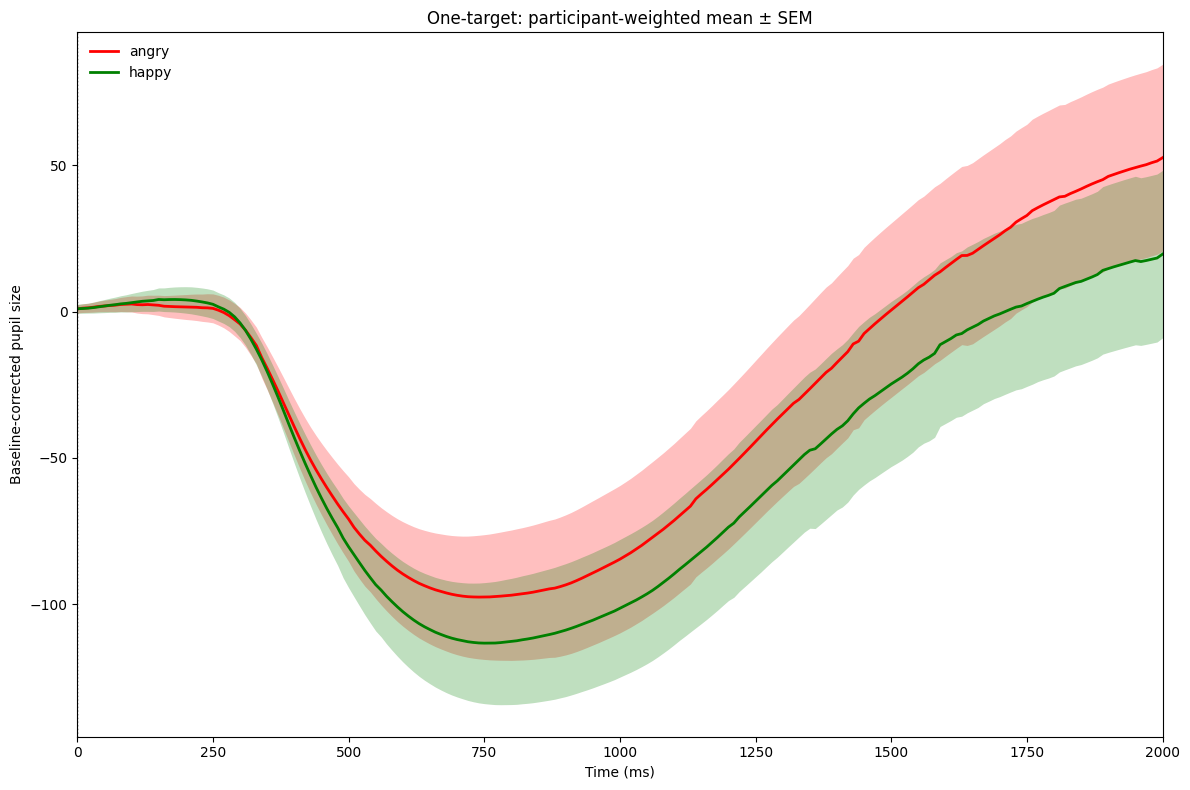

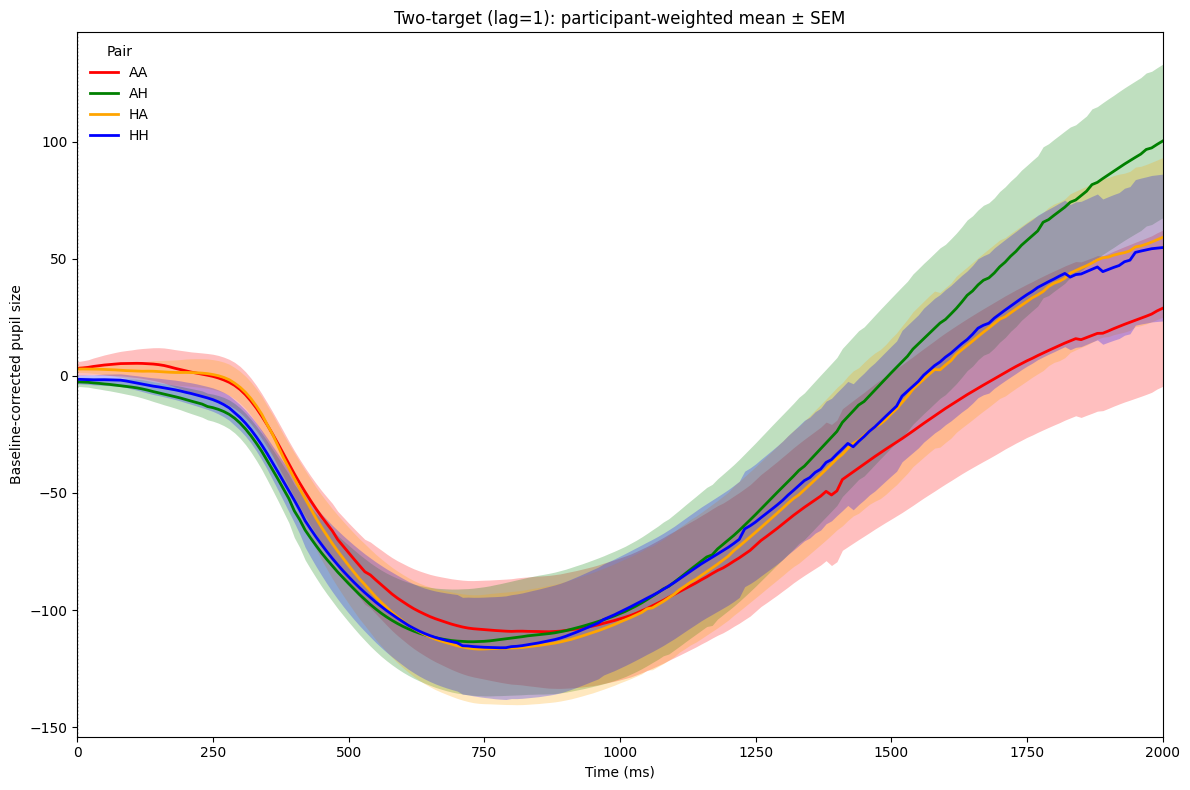

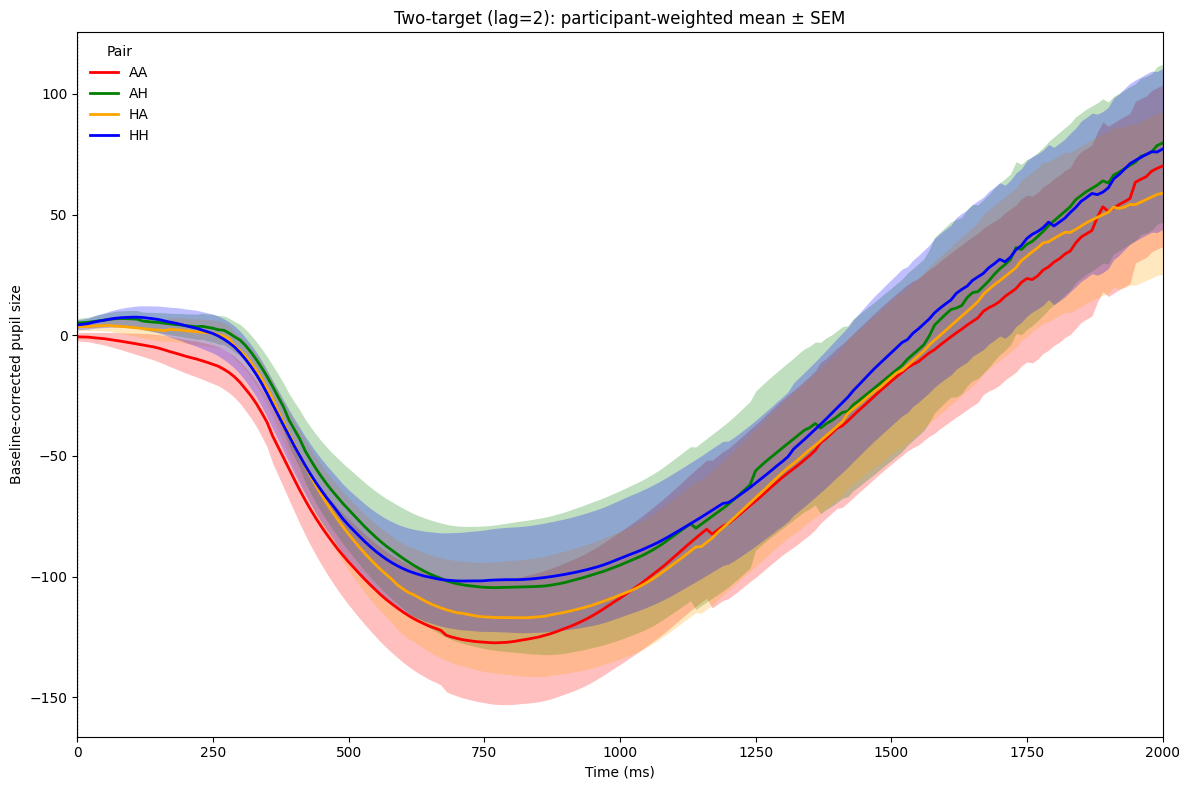

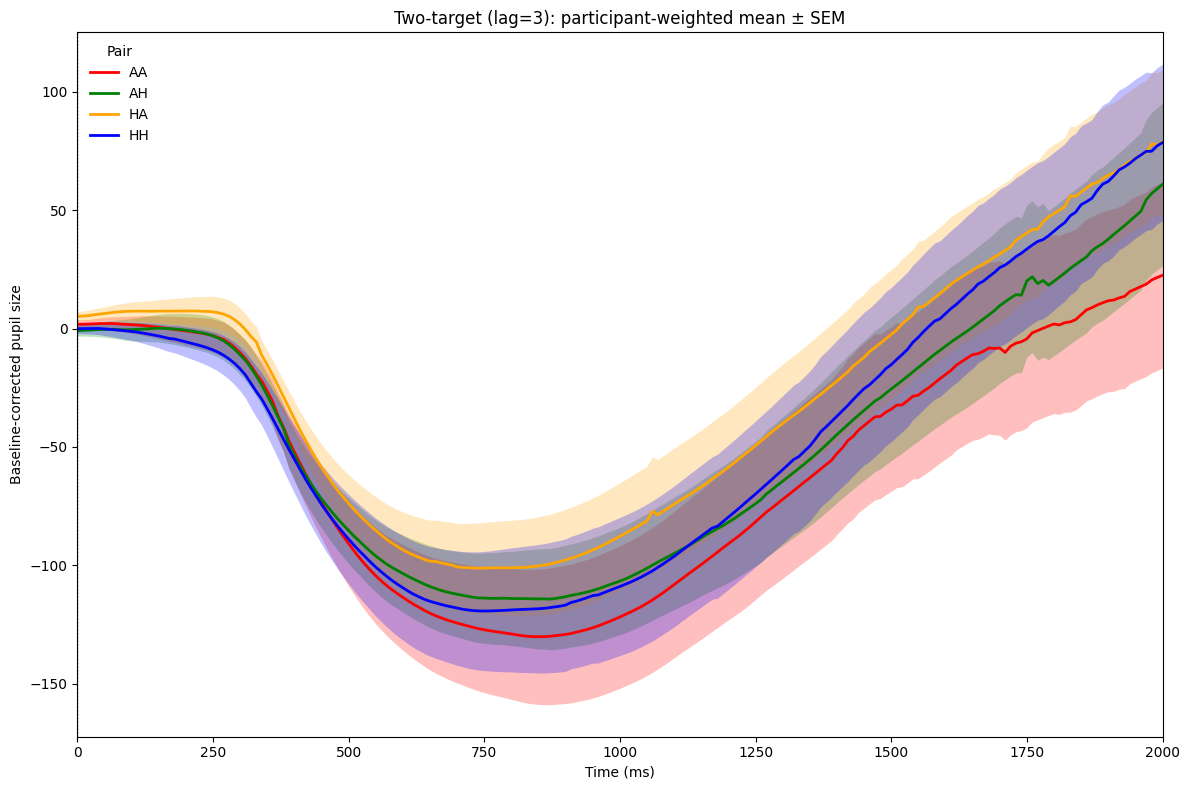

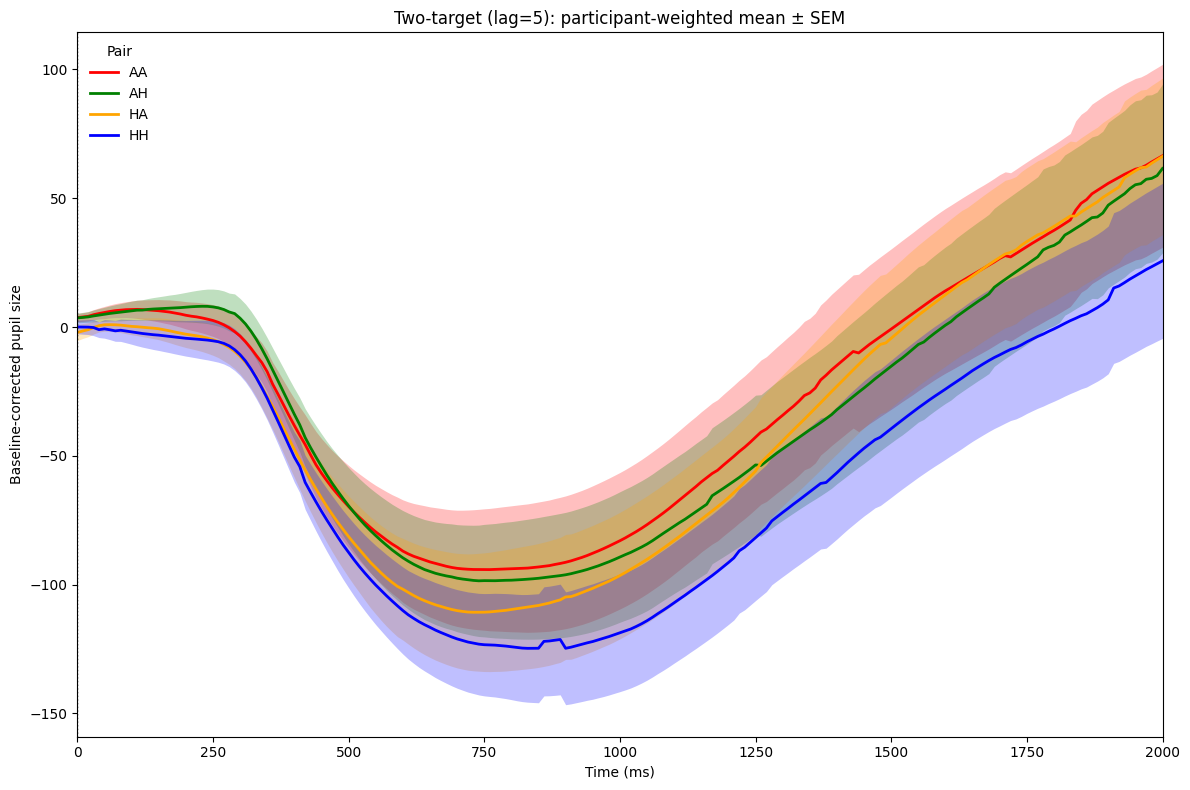

In [10]:

save_folder = r"/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Updated_Preprocessed_Data"

EXCLUDE_PIDS = {"P36", "P6", "P24", "P25","P35"}  # Filter based on accuracy

PUPIL_COL = "ptrace_RSVP"
TTRACE_COL = "ttrace_RSVP"

T_MIN_MS, T_MAX_MS = 0, 2000
T0_MODE = "start"  # "start" or None

ONE_TARGET_PAIRS = {"HN": "happy", "AN": "angry"}
TWO_TARGET_PAIRS = ["HH", "HA", "AA", "AH"]
LAGS = [1, 2, 3, 5]




def ms_axis(dm, tcol=TTRACE_COL):
    T = np.asarray(dm[tcol], float)
    if T0_MODE == "start":
        T = T - T[:, [0]]
    x = np.nanmedian(T, axis=0)

    # fill NaNs in x if needed (robust plotting)
    if np.isnan(x).any():
        idx = np.arange(x.size)
        good = ~np.isnan(x)
        x = np.interp(idx, idx[good], x[good]) if good.sum() >= 2 else idx.astype(float)

    keep = (x >= T_MIN_MS) & (x <= T_MAX_MS)
    return x, keep


def build_trials(all_dms, selector, annotate=None):

    chunks = []
    for pid, dm in sorted(all_dms.items()):
        if len(dm) == 0:
            continue
        sel = selector(pid, dm)
        if len(sel) == 0:
            continue
        if annotate:
            annotate(sel, pid, dm)
        chunks.append(sel)
    return ops.stack(chunks) if chunks else DataMatrix(length=0)


def participant_means(dm_trials, dv, factors):
    # group by (participant, factor levels...) then average within each group (over trials)
    buckets = {}
    for row in dm_trials:
        key = (row.participant,) + tuple(getattr(row, f) for f in factors)
        buckets.setdefault(key, []).append(np.asarray(getattr(row, dv), float))

    keys = list(buckets.keys())
    pm = DataMatrix(length=len(keys))
    pm.participant = ""
    for f in factors:
        pm[f] = ""
    pm[dv] = SeriesColumn(depth=dm_trials[dv].depth)

    for i, k in enumerate(keys):
        pm.participant[i] = k[0]
        for j, f in enumerate(factors, start=1):
            pm[f][i] = k[j]
        pm[dv][i] = np.nanmean(np.vstack(buckets[k]), axis=0)

    return pm


def mean_sem_by_level(pm, dv, factor):
    out = {}
    for lev in sorted(set(getattr(pm, factor))):
        sub = getattr(pm, factor) == lev
        X = np.asarray(sub[dv], float)  # (n_participants, depth)
        m = np.nanmean(X, axis=0)
        n = np.sum(~np.isnan(X), axis=0)
        sd = np.nanstd(X, axis=0, ddof=1)
        sem = sd / np.sqrt(np.maximum(n, 1))
        out[lev] = (m, sem, len(sub))
    return out


def plot_stats(x, keep, stats, title, colors=None, legend_title=None):
    plt.figure(figsize=(12, 8))
    for level, (m, sem, nP) in stats.items():
        c = (colors or {}).get(level, "black")
        plt.fill_between(x[keep], (m - sem)[keep], (m + sem)[keep], color=c, alpha=0.25, linewidth=0)
        plt.plot(x[keep], m[keep], color=c, lw=2, label=f"{level}")

    plt.axvline(0, ls=":", c="black", lw=1)
    plt.xlim(T_MIN_MS, T_MAX_MS)
    plt.xlabel("Time (ms)")
    plt.ylabel("Baseline-corrected pupil size")
    plt.title(title)
    plt.legend(frameon=False, title=legend_title)
    plt.tight_layout()
    plt.show()


# -----------------------
# LOAD DMs
# -----------------------
all_dms = {}
for path in sorted(glob.glob(os.path.join(save_folder, "P*_dm_preprocessed.dm"))):
    pid = os.path.basename(path).split("_dm_preprocessed.dm")[0]
    if pid in EXCLUDE_PIDS:
        continue
    all_dms[pid] = io.readbin(path)

print(f"Loaded {len(all_dms)} participants (excluded: {sorted(EXCLUDE_PIDS)})")


dm_one = build_trials(
    all_dms,
    selector=lambda pid, dm: ops.stack([
        ((dm.two_targets == 0) & (dm.pair == pair_code))
        for pair_code in ONE_TARGET_PAIRS.keys()
    ]) if len(dm) else DataMatrix(length=0),
    annotate=lambda sel, pid, dm: (
        setattr(sel, "participant", pid),
        setattr(sel, "emotion", ["happy" if p == "HN" else "angry" for p in sel.pair]),
    ),
)

dm_two = build_trials(
    all_dms,
    selector=lambda pid, dm: (dm.two_targets == 1),
    annotate=lambda sel, pid, dm: (
        setattr(sel, "participant", pid),
        setattr(sel, "lag", (sel.T2_pos - sel.T1_pos)),
    ),
)

# keep only relevant conditions for 2-target analyses
if len(dm_two):
    dm_two = (dm_two.pair == set(TWO_TARGET_PAIRS)) & (dm_two.lag == set(LAGS))


# -----------------------
# PLOT 1: ONE-TARGET
# -----------------------

x_ms, keep = ms_axis(dm_one)

pm = participant_means(dm_one, dv=PUPIL_COL, factors=["emotion"])
stats = mean_sem_by_level(pm, dv=PUPIL_COL, factor="emotion")
plot_stats(
    x_ms, keep, stats,
    title="One-target: participant-weighted mean ± SEM",
    colors={"happy": "green", "angry": "red"},
)


# -----------------------
# PLOT 2+: TWO-TARGET BY LAG
# -----------------------

x_ms, keep = ms_axis(dm_two)

colors_two = {"HH": "blue", "HA": "orange", "AA": "red", "AH": "green"}

for lg in LAGS:
    dm_lag = (dm_two.lag == lg)
    if len(dm_lag) == 0:
        print(f"Skipping lag={lg}: no trials.")
        continue

    pm = participant_means(dm_lag, dv=PUPIL_COL, factors=["pair"])
    stats = mean_sem_by_level(pm, dv=PUPIL_COL, factor="pair")
    plot_stats(
        x_ms, keep, stats,
        title=f"Two-target (lag={lg}): participant-weighted mean ± SEM",
        colors=colors_two,
        legend_title="Pair",
    )

## Blink vs No Blink Condition divide based on emotion

Loaded 32 participants (excluded: ['P24', 'P25', 'P35', 'P36', 'P6'])


/tmp/ipykernel_9054/488473055.py:50: RuntimeWarning: Mean of empty slice
  pm[dv][i] = np.nanmean(X, axis=0)
/tmp/ipykernel_9054/103899482.py:16: RuntimeWarning: Mean of empty slice
  m = np.nanmean(X, axis=0)


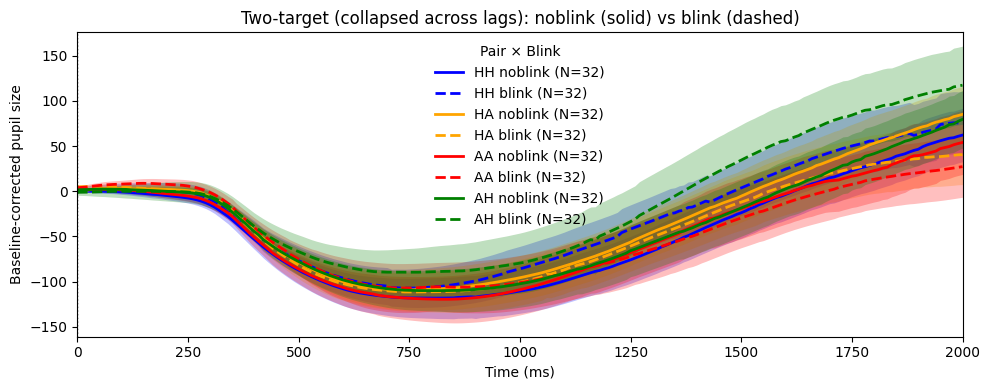

In [12]:


PAIR_KEYS = {
    "HH": {"first_key": "a", "third_key": "a"},
    "HA": {"first_key": "a", "third_key": "l"},
    "AA": {"first_key": "l", "third_key": "l"},
    "AH": {"first_key": "l", "third_key": "a"},
}



def mean_sem_by_level(pm, dv, factor):
    out = {}
    levels = sorted(set(getattr(pm, factor)))
    for lev in levels:
        sub = getattr(pm, factor) == lev
        X = np.asarray(sub[dv], float)
        m = np.nanmean(X, axis=0)
        n = np.sum(~np.isnan(X), axis=0)
        sd = np.nanstd(X, axis=0, ddof=1)
        sem = sd / np.sqrt(np.maximum(n, 1))
        out[lev] = (m, sem, len(sub))
    return out


def plot_mean_sem(x, m, sem, label, color="black", lw=2, band_alpha=0.25, linestyle="-"):
    plt.fill_between(x, m - sem, m + sem, color=color, alpha=band_alpha, linewidth=0)
    plt.plot(x, m, color=color, linewidth=lw, label=label, linestyle=linestyle)


def masks_for_pair(dm, pair_code):
    keys = PAIR_KEYS[pair_code]
    first_key = keys["first_key"]
    third_key = keys["third_key"]

    t1_correct = (dm.response_first_resp == first_key)

    t2_second_ok = (dm.second_resp == "l")
    t2_third_ok = (dm.response_third_response == third_key)
    t2_correct = t2_second_ok & t2_third_ok

    # "incorrect" explicitly
    t2_incorrect = (dm.second_resp != "l") | (dm.response_third_response != third_key)

    return t1_correct, t2_correct, t2_incorrect



all_dms = {}
for path in sorted(glob.glob(os.path.join(save_folder, "P*_dm_preprocessed.dm"))):
    pid = os.path.basename(path).split("_dm_preprocessed.dm")[0]
    if pid in EXCLUDE_PIDS:
        continue
    all_dms[pid] = io.readbin(path)

print(f"Loaded {len(all_dms)} participants (excluded: {sorted(EXCLUDE_PIDS)})")


trials_two = []
for pid, dm in sorted(all_dms.items()):
    if len(dm) == 0:
        continue

    dm.participant = pid

    for pair_code in TWO_TARGET_PAIRS:
        t1_corr, t2_corr, t2_inc = masks_for_pair(dm, pair_code)

        for lg in LAGS:
            base = (dm.two_targets == 1) & (dm.pair == pair_code) & ((dm.T2_pos - dm.T1_pos) == lg)

            sel_nb = base & t1_corr & t2_corr
            if len(sel_nb):
                sel_nb.participant = pid
                sel_nb.pair = pair_code
                sel_nb.lag = lg
                sel_nb.blink_state = "noblink"
                trials_two.append(sel_nb)

            sel_b = base & t1_corr & t2_inc
            if len(sel_b):
                sel_b.participant = pid
                sel_b.pair = pair_code
                sel_b.lag = lg
                sel_b.blink_state = "blink"
                trials_two.append(sel_b)

dm_two = ops.stack(trials_two) if trials_two else DataMatrix(length=0)

if len(dm_two) == 0:
    print("No two-target trials found.")
else:
    for required in [PUPIL_COL, TTRACE_COL]:
        if required not in dm_two.column_names:
            raise KeyError(f"Missing column: {required}. Available: {dm_two.column_names}")

    x_ms, keep = ms_axis(dm_two, TTRACE_COL)

    colors_two = {"HH": "blue", "HA": "orange", "AA": "red", "AH": "green"}
    linestyles = {"noblink": "-", "blink": "--"}

    plt.figure(figsize=(10, 4))

    for pair_code in TWO_TARGET_PAIRS:
        for state in ["noblink", "blink"]:
            dm_sel = (dm_two.pair == pair_code) & (dm_two.blink_state == state)
            if len(dm_sel) == 0:
                continue

            # participant-weighted: average trials within participant first
            pm = participant_means(dm_sel, dv=PUPIL_COL, factors=["blink_state"])
            stats = mean_sem_by_level(pm, dv=PUPIL_COL, factor="blink_state")
            m, sem, nP = stats[state]

            plot_mean_sem(
                x_ms[keep],
                m[keep],
                sem[keep],
                label=f"{pair_code} {state} (N={nP})",
                color=colors_two.get(pair_code, "black"),
                linestyle=linestyles[state],
            )

    plt.axvline(0, linestyle=":", color="black", linewidth=1)
    plt.xlim(T_MIN_MS, T_MAX_MS)
    plt.xlabel("Time (ms)")
    plt.ylabel("Baseline-corrected pupil size")
    plt.title("Two-target (collapsed across lags): noblink (solid) vs blink (dashed)")
    plt.legend(frameon=False, title="Pair × Blink")
    plt.tight_layout()
    plt.show()

/tmp/ipython-input-3712126046.py:67: RuntimeWarning: Mean of empty slice
  pm[dv][i] = np.nanmean(np.vstack(buckets[k]), axis=0)
/tmp/ipython-input-1068069016.py:6: RuntimeWarning: Mean of empty slice
  m = np.nanmean(X, axis=0)


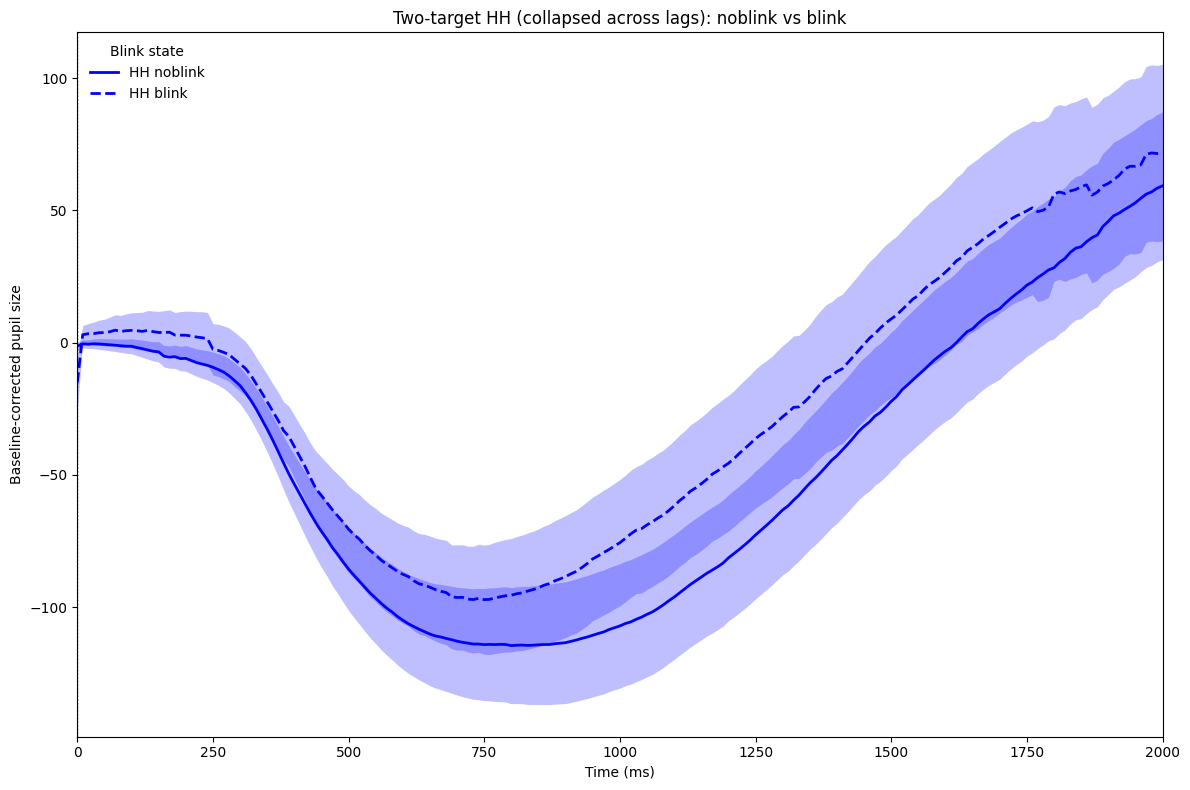

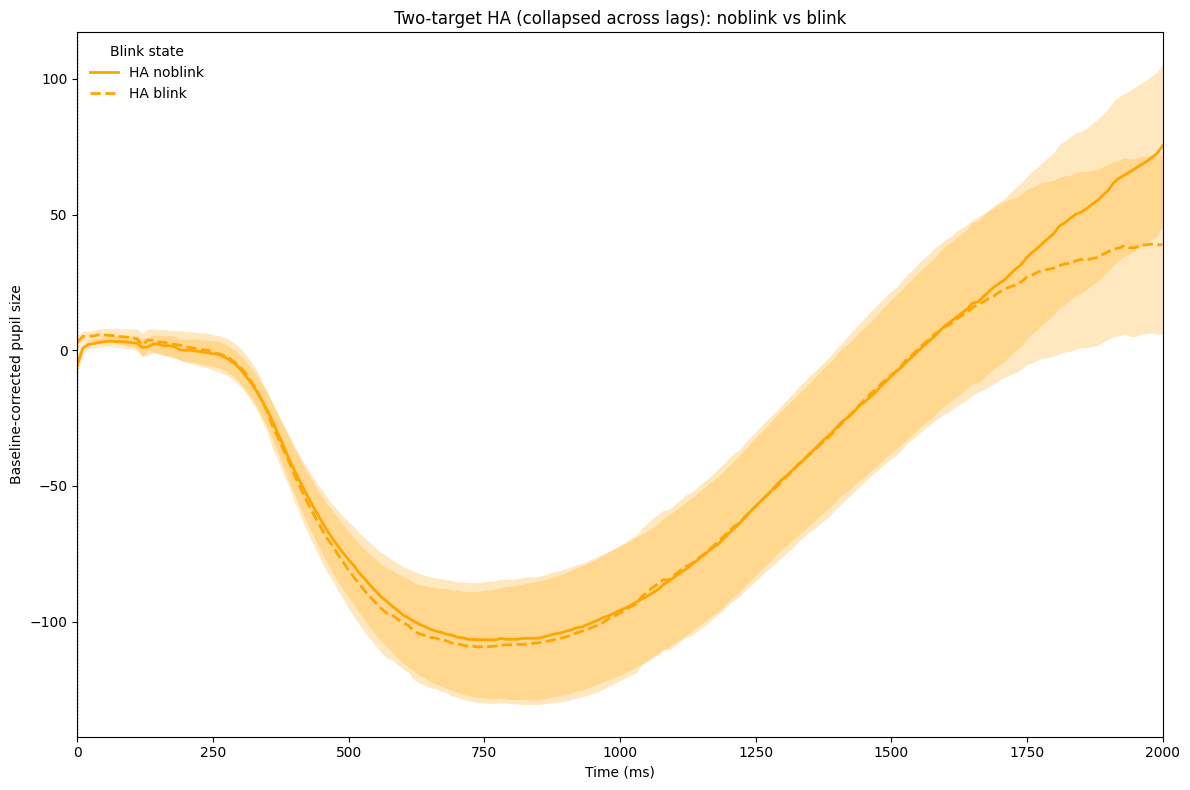

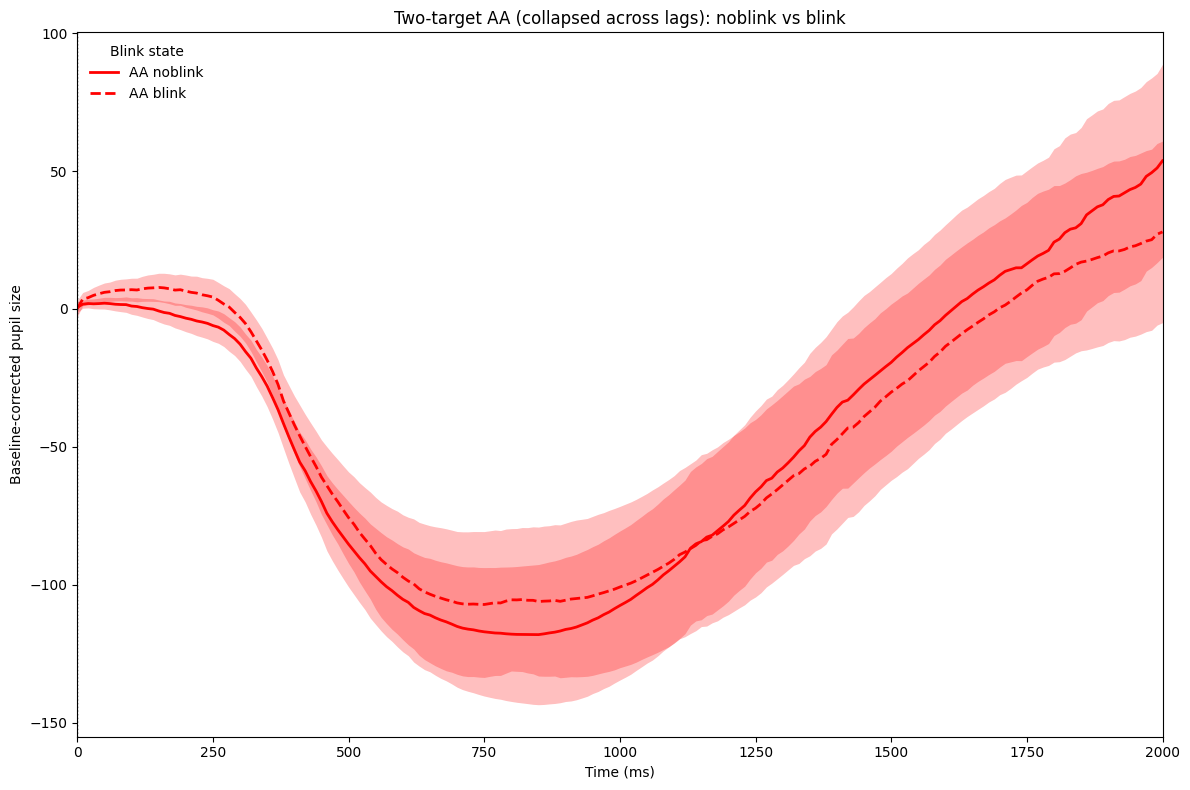

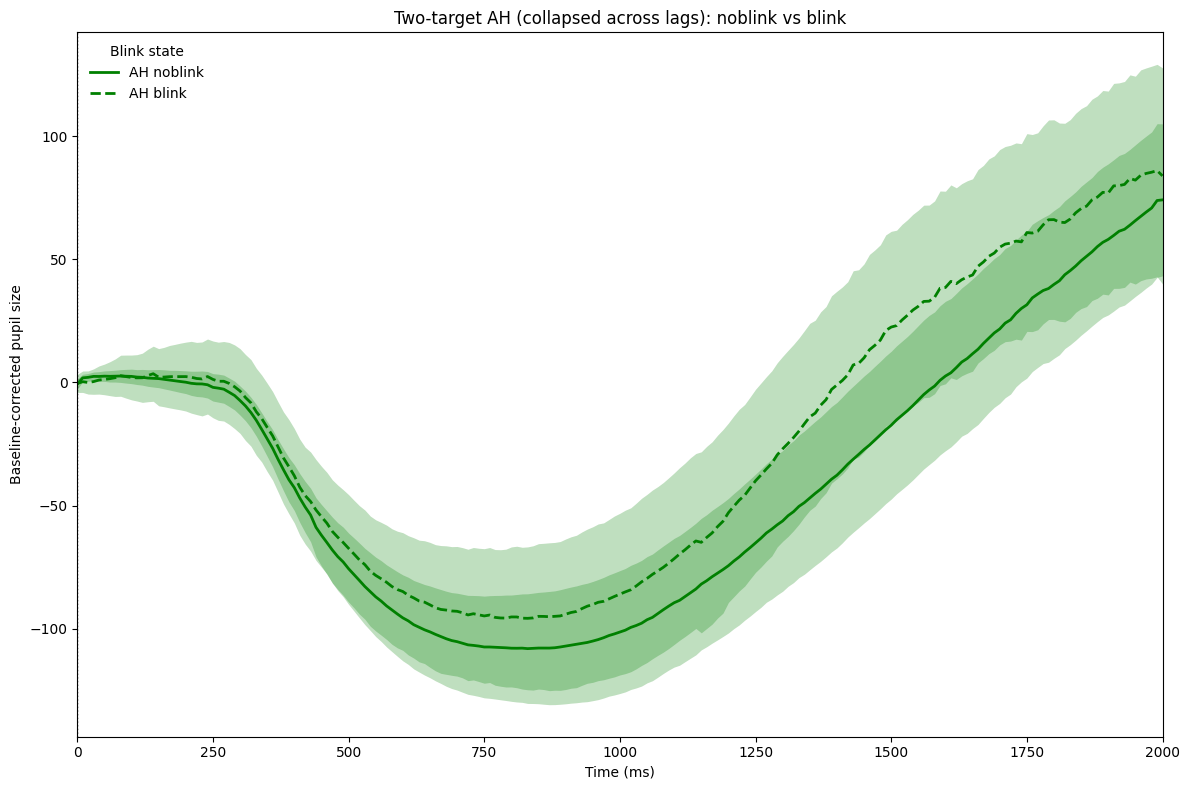

In [ ]:



x_ms, keep = ms_axis(dm_two, TTRACE_COL)

colors_two = {"HH": "blue", "HA": "orange", "AA": "red", "AH": "green"}
linestyles = {"noblink": "-", "blink": "--"}

for pair_code in TWO_TARGET_PAIRS:
    plt.figure(figsize=(12, 8))

    for state in ["noblink", "blink"]:
        dm_sel = (dm_two.pair == pair_code) & (dm_two.blink_state == state)
        if len(dm_sel) == 0:
            print(f"Skipping {pair_code} / {state}: no trials.")
            continue

        # participant-weighted: average trials within participant first
        pm = participant_means(dm_sel, dv=PUPIL_COL, factors=["blink_state"])
        stats = mean_sem_by_level(pm, dv=PUPIL_COL, factor="blink_state")

        # If a state is missing entirely, it won't be in stats
        if state not in stats:
            print(f"Skipping {pair_code} / {state}: no participant means.")
            continue

        m, sem, nP = stats[state]

        plot_mean_sem(
            x_ms[keep],
            m[keep],
            sem[keep],
            label=f"{pair_code} {state}",
            color=colors_two.get(pair_code, "black"),
            linestyle=linestyles[state],
        )

    plt.axvline(0, linestyle=":", color="black", linewidth=1)
    plt.xlim(T_MIN_MS, T_MAX_MS)
    plt.xlabel("Time (ms)")
    plt.ylabel("Baseline-corrected pupil size")
    plt.title(f"Two-target {pair_code} (collapsed across lags): noblink vs blink")
    plt.legend(frameon=False, title="Blink state")
    plt.tight_layout()
    plt.show()

## Blink vs No Blink divided based on emotions but grouped based on noblink or blink

/tmp/ipykernel_9054/488473055.py:50: RuntimeWarning: Mean of empty slice
  pm[dv][i] = np.nanmean(X, axis=0)
/tmp/ipykernel_9054/103899482.py:16: RuntimeWarning: Mean of empty slice
  m = np.nanmean(X, axis=0)


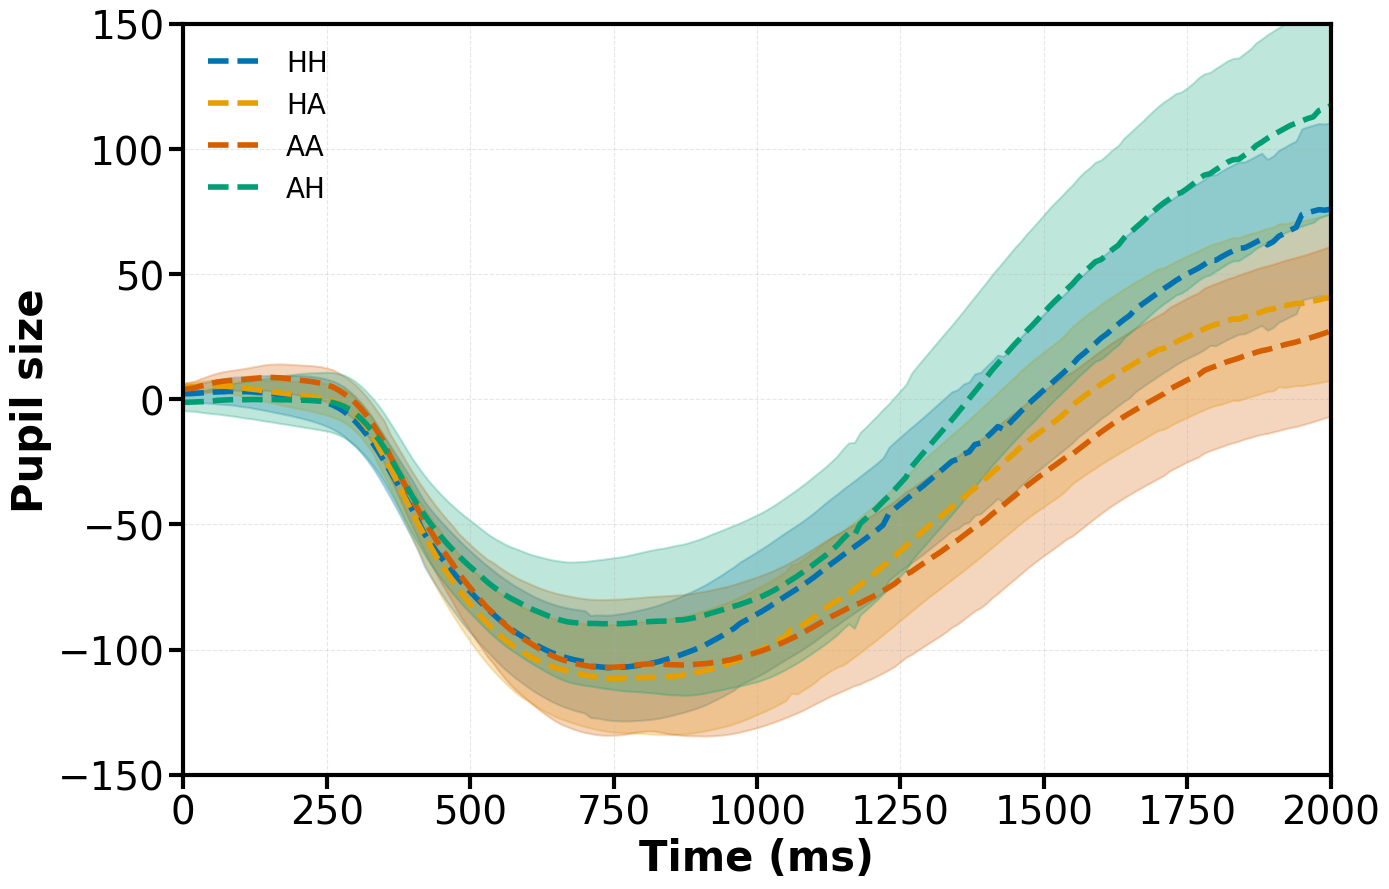

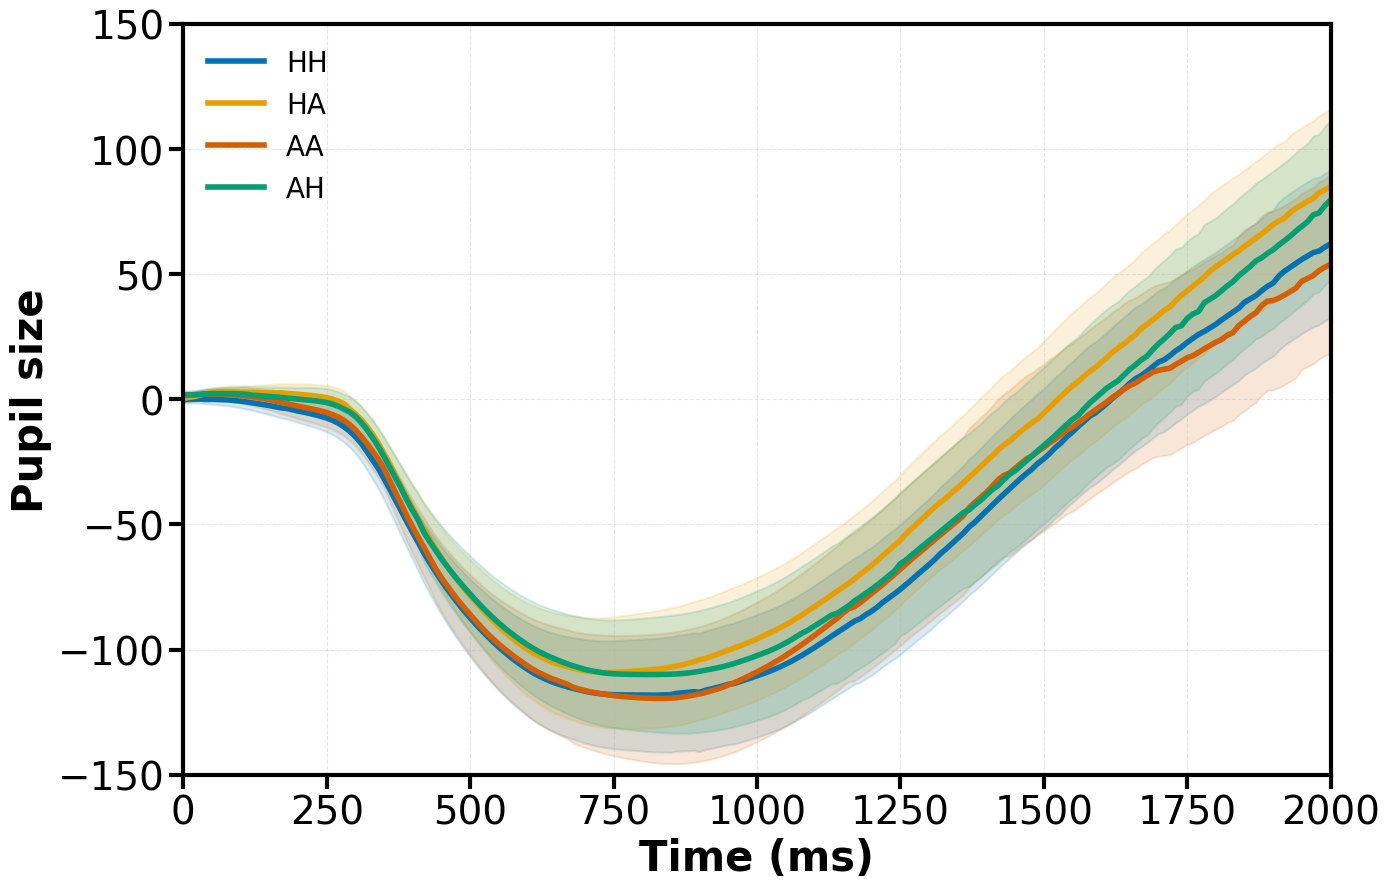

In [21]:
# --------------------------------------------------
# 🎨 FIXED COLOR PALETTE (REFERENCE STYLE)
# --------------------------------------------------
COLOR_MAP = {
    "HH": "#0072B2",  # blue
    "HA": "#E69F00",  # orange
    "AA": "#D55E00",  # red
    "AH": "#009E73"   # green
}

# --------------------------------------------------
# 🔥 PLOTTING FUNCTION
# --------------------------------------------------
def plot_state(state_label, title):

    fig, ax = plt.subplots(figsize=(14, 9))

    for pair_code in TWO_TARGET_PAIRS:

        # 🔴 Ensure clean key (avoids hidden bugs like "HH ")
        pair_code_clean = str(pair_code).strip()

        dm_sel = (dm_two.pair == pair_code_clean) & (dm_two.blink_state == state_label)
        if len(dm_sel) == 0:
            print(f"Skipping {state_label} / {pair_code_clean}: no trials.")
            continue

        pm = participant_means(dm_sel, dv=PUPIL_COL, factors=["blink_state"])
        stats = mean_sem_by_level(pm, dv=PUPIL_COL, factor="blink_state")

        if state_label not in stats:
            print(f"Skipping {state_label} / {pair_code_clean}: no participant means.")
            continue

        m, sem, nP = stats[state_label]

        # 🔥 FORCE COLOR (no fallback)
        if pair_code_clean not in COLOR_MAP:
            raise ValueError(f"Unknown pair: {pair_code_clean}")

        color = COLOR_MAP[pair_code_clean]

        # 🔴 STYLE RULES
        if state_label == "blink":
            linestyle = "--"
            alpha = 0.25
        else:
            linestyle = "-"
            alpha = 0.15

        # --------------------------------------------------
        # CI (with visible border)
        # --------------------------------------------------
        ax.fill_between(
            x_ms[keep],
            m[keep] - sem[keep],
            m[keep] + sem[keep],
            facecolor=color,
            alpha=alpha,
            edgecolor=color,
            linewidth=1.5
        )

        # --------------------------------------------------
        # MAIN LINE (STRONG + CLEAR)
        # --------------------------------------------------
        ax.plot(
            x_ms[keep],
            m[keep],
            color=color,
            linewidth=4,
            linestyle=linestyle,
            label=f"{pair_code_clean}"
        )

    # --------------------------------------------------
    # FORMATTING (PUBLICATION READY)
    # --------------------------------------------------
    ax.axvline(0, linestyle="--", color="black", linewidth=2)

    ax.set_xlim(T_MIN_MS, T_MAX_MS)
    ax.set_ylim(-150, 150)
    ax.set_yticks(np.arange(-150, 151, 50))

    ax.set_xlabel("Time (ms)", fontsize=30, fontweight='bold')
    ax.set_ylabel("Pupil size", fontsize=30, fontweight='bold')

    ax.tick_params(axis='both', labelsize=28, width=3, length=10)

    # thick borders
    for spine in ax.spines.values():
        spine.set_linewidth(3)

    ax.grid(True, linestyle='--', alpha=0.3)

    ax.legend(fontsize=20, frameon=False)

    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# 🔥 RUN PLOTS
# --------------------------------------------------
plot_state("blink", "Two-target (collapsed across lags): BLINK trials")
plot_state("noblink", "Two-target (collapsed across lags): NO-BLINK trials")

## Blink vs No Blink

/tmp/ipykernel_9054/488473055.py:50: RuntimeWarning: Mean of empty slice
  pm[dv][i] = np.nanmean(X, axis=0)
/usr/local/lib/python3.12/dist-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_9054/103899482.py:16: RuntimeWarning: Mean of empty slice
  m = np.nanmean(X, axis=0)


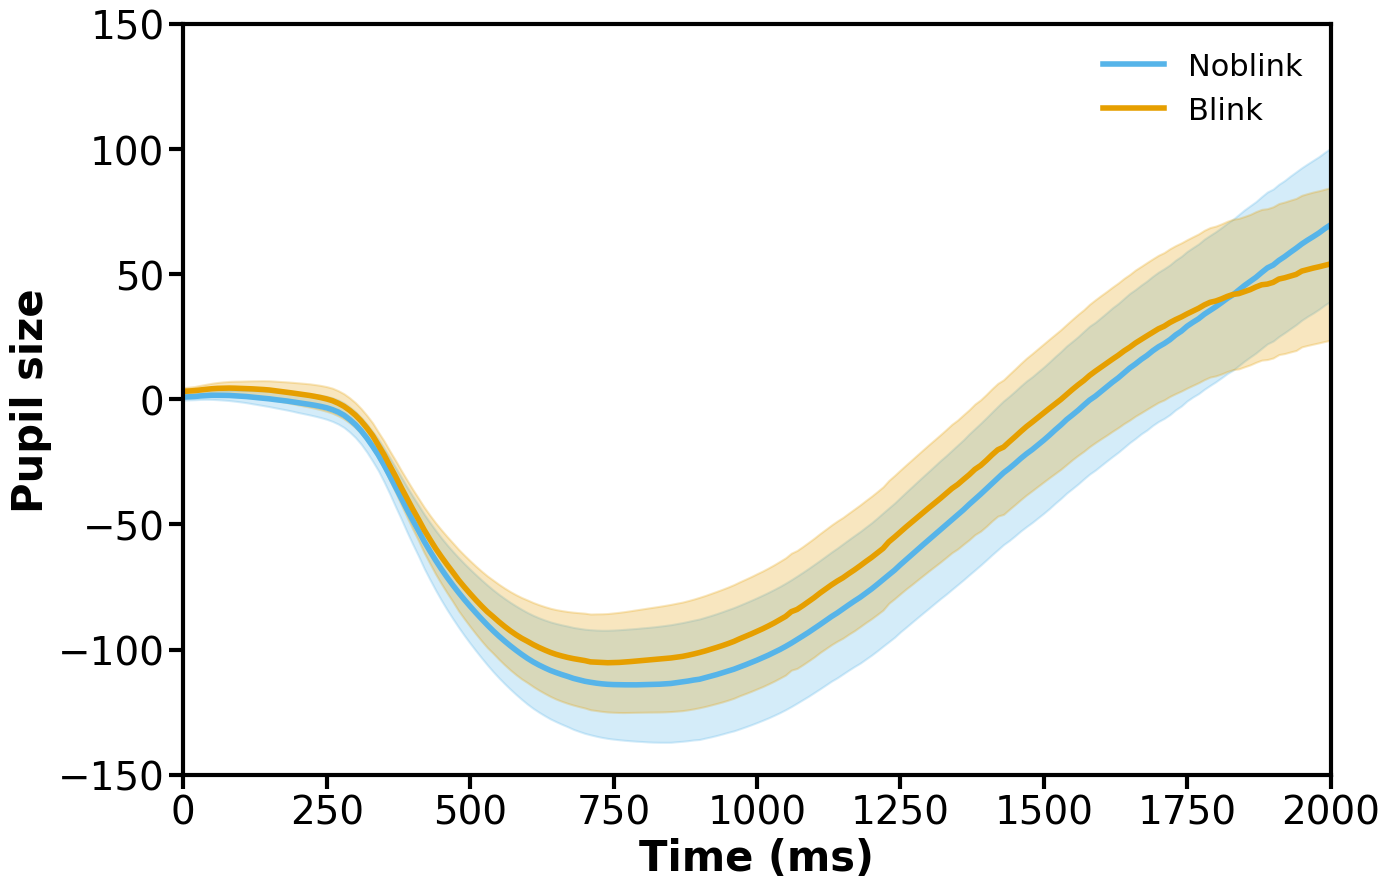

In [25]:
# --------------------------------------------------
# 🔥 UPDATED BLINK vs NO-BLINK PLOT (REFERENCE STYLE)
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

# 🎨 MATCH REFERENCE COLORS
styles = {
    "noblink": dict(color="#56B4E9", linestyle="-", lw=4),  # sky blue
    "blink":   dict(color="#E69F00", linestyle="-", lw=4),  # orange
}

for state in ["noblink", "blink"]:

    dm_sel = (dm_two.blink_state == state)
    if len(dm_sel) == 0:
        print(f"Skipping {state}: no trials.")
        continue

    # participant-weighted mean
    pm = participant_means(
        dm_sel,
        dv=PUPIL_COL,
        factors=["blink_state"]
    )

    stats = mean_sem_by_level(
        pm,
        dv=PUPIL_COL,
        factor="blink_state"
    )

    if state not in stats:
        print(f"Skipping {state}: no participant means.")
        continue

    m, sem, nP = stats[state]

    color = styles[state]["color"]

    # 🔵 MAIN LINE
    ax.plot(
        x_ms[keep],
        m[keep],
        label=f"{state.replace('_',' ').title()}",
        **styles[state]
    )

    # 🔵 CI (WITH BORDER — IMPORTANT)
    ax.fill_between(
        x_ms[keep],
        m[keep] - sem[keep],
        m[keep] + sem[keep],
        facecolor=color,
        alpha=0.25,
        edgecolor=color,
        linewidth=1.5
    )




ax.set_xlim(T_MIN_MS, T_MAX_MS)

# auto y scaling (cleaner than fixed)
y_min = np.nanmin([m[keep] - sem[keep]])
y_max = np.nanmax([m[keep] + sem[keep]])
ax.set_ylim(y_min - 5, y_max + 5)

# labels
ax.set_xlabel("Time (ms)", fontsize=30, fontweight='bold')
ax.set_ylabel("Pupil size", fontsize=30, fontweight='bold')

# ticks
ax.tick_params(axis='both', labelsize=28, width=3, length=10)

# thick spines
for spine in ax.spines.values():
    spine.set_linewidth(3)

# grid
ax.grid(True, linestyle='--', alpha=0.4)

# legend
ax.legend(fontsize=22, frameon=False)
plt.ylim(-150,150)
plt.grid(False)

plt.tight_layout()
plt.show()

## Two target vs One target

Loaded 32 participants


/tmp/ipykernel_9054/488473055.py:50: RuntimeWarning: Mean of empty slice
  pm[dv][i] = np.nanmean(X, axis=0)
/usr/local/lib/python3.12/dist-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_9054/3960284294.py:6: RuntimeWarning: Mean of empty slice
  m = np.nanmean(X, axis=0)


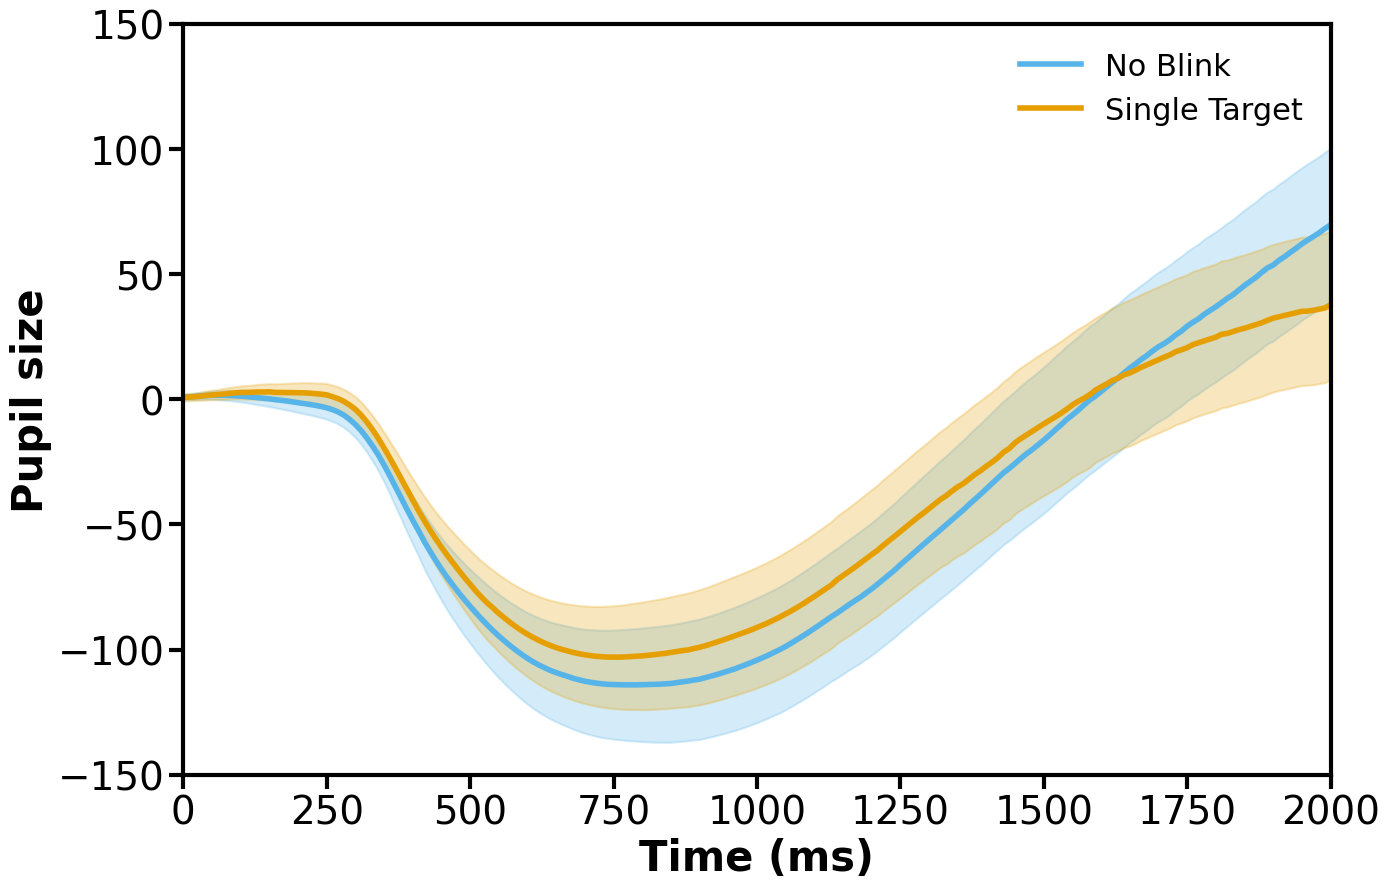

In [30]:


def mean_sem_by_level(pm, dv, factor):
    out = {}
    for lev in sorted(set(getattr(pm, factor))):
        sub = getattr(pm, factor) == lev
        X = np.asarray(sub[dv], float)
        m = np.nanmean(X, axis=0)
        sd = np.nanstd(X, axis=0, ddof=1)
        sem = sd / np.sqrt(X.shape[0])
        out[lev] = (m, sem, X.shape[0])
    return out


def plot_mean_sem(x, m, sem, label, color="black", lw=2, band_alpha=0.25, linestyle="-"):
    plt.fill_between(x, m - sem, m + sem, color=color, alpha=band_alpha, linewidth=0)
    plt.plot(x, m, color=color, lw=lw, linestyle=linestyle, label=label)


def masks_for_pair(dm, pair_code):
    keys = PAIR_KEYS[pair_code]


    t1_correct = (dm.response_first_resp == keys["first_key"])


    t2_correct = (
        (dm.second_resp == "l") &
        (dm.response_third_response == keys["third_key"])
    )

    t2_incorrect = (
        (dm.second_resp != "l") |
        (dm.response_third_response != keys["third_key"])
    )

    return t1_correct, t2_correct, t2_incorrect

all_dms = {}
for path in sorted(glob.glob(os.path.join(save_folder, "P*_dm_preprocessed.dm"))):
    pid = os.path.basename(path).split("_dm_preprocessed.dm")[0]
    if pid in EXCLUDE_PIDS:
        continue
    all_dms[pid] = io.readbin(path)

print(f"Loaded {len(all_dms)} participants")


trials_two = []

for pid, dm in all_dms.items():
    dm.participant = pid

    for pair_code in TWO_TARGET_PAIRS:
        t1_corr, t2_corr, t2_inc = masks_for_pair(dm, pair_code)

        for lg in LAGS:
            base = (
                (dm.two_targets == 1) &
                (dm.pair == pair_code) &
                ((dm.T2_pos - dm.T1_pos) == lg)
            )

            nb = base & t1_corr & t2_corr
            if len(nb):
                nb.participant = pid
                nb.blink_state = "noblink"
                trials_two.append(nb)

            b = base & t1_corr & t2_inc
            if len(b):
                b.participant = pid
                b.blink_state = "blink"
                trials_two.append(b)

dm_two = ops.stack(trials_two)

trials_one = []

for pid, dm in all_dms.items():
    dm.participant = pid

    # HN
    sel_h = (
        (dm.two_targets == 0) &
        (dm.pair == "HN") &
        (dm.response_first_resp == "a") &
        (dm.second_resp == "a")
    )
    if len(sel_h):
        sel_h.participant = pid
        sel_h.condition = "one_target"
        trials_one.append(sel_h)

    # AN
    sel_a = (
        (dm.two_targets == 0) &
        (dm.pair == "AN") &
        (dm.response_first_resp == "l") &
        (dm.second_resp == "a")
    )
    if len(sel_a):
        sel_a.participant = pid
        sel_a.condition = "one_target"
        trials_one.append(sel_a)

dm_one = ops.stack(trials_one)


dm_two_nb = (dm_two.blink_state == "noblink")
dm_two_nb.condition = "two_target_noblink"

dm_compare = ops.stack([dm_two_nb, dm_one])


x_ms, keep = ms_axis(dm_compare, TTRACE_COL)

# --------------------------------------------------
# 🔥 UPDATED PLOT (MATCHES REFERENCE STYLE)
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

# 🎨 MATCH REFERENCE COLORS
styles = {
    "two_target_noblink": dict(color="#56B4E9", linestyle="-", lw=4),  # sky blue
    "one_target":        dict(color="#E69F00", linestyle="-", lw=4),  # orange
}

store_curves = {}
label_map = {
    "two_target_noblink": "No Blink",
    "one_target": "Single Target"
}

for cond in ["two_target_noblink", "one_target"]:

    dm_sel = (dm_compare.condition == cond)

    pm = participant_means(dm_sel, PUPIL_COL, ["condition"])
    stats = mean_sem_by_level(pm, PUPIL_COL, "condition")

    if cond not in stats:
        continue

    m, sem, nP = stats[cond]
    store_curves[cond] = (m[keep], sem[keep])

    color = styles[cond]["color"]

    ax.plot(
        x_ms[keep],
        m[keep],
        label=label_map[cond],   # 🔥 CLEAN LABEL
        **styles[cond]
    )

    ax.fill_between(
        x_ms[keep],
        m[keep] - sem[keep],
        m[keep] + sem[keep],
        facecolor=color,
        alpha=0.25,
        edgecolor=color,
        linewidth=1.5
    )


# --------------------------------------------------
# OPTIONAL: AUTO Y-LIMIT (PREVENT CLIPPING)
# --------------------------------------------------
all_mins = []
all_maxs = []

for m, sem in store_curves.values():
    all_mins.append(np.nanmin(m - sem))
    all_maxs.append(np.nanmax(m + sem))

y_min = np.min(all_mins)
y_max = np.max(all_maxs)

ax.set_ylim(y_min - 5, y_max + 5)

# --------------------------------------------------
# BEAUTIFICATION (MATCH REFERENCE)
# --------------------------------------------------
ax.set_xlim(T_MIN_MS, T_MAX_MS)

ax.set_xlabel("Time (ms)", fontsize=30, fontweight='bold')
ax.set_ylabel("Pupil size", fontsize=30, fontweight='bold')

ax.tick_params(axis='both', labelsize=28, width=3, length=10)

# thick spines
for spine in ax.spines.values():
    spine.set_linewidth(3)

# grid
ax.grid(True, linestyle='--', linewidth=1.5, alpha=0.4)

# legend
ax.legend(fontsize=22, frameon=False)
plt.ylim(-150,150)
plt.grid(False)

plt.tight_layout()
plt.show()
